# 00 · Setup, controllo dati e baseline

**Obiettivo.** Prima di cercare cluster o sottogruppi serve sapere *quanto segnale c'è* nelle feature tabulari. Questo notebook:

1. carica EchoNext e verifica che split, pazienti ed etichette siano coerenti;
2. mostra prevalenze e valori mancanti;
3. addestra più modelli sul target composito `shd_moderate_or_greater_flag` e li confronta con un riferimento "solo età + sesso".

**Cosa serve.** I file di EchoNext (accesso ristretto, DUA firmato su PhysioNet) in `/home/teo/Desktop/dataset`, cambiabile in `DATA_DIR` nella cella di setup. Va bene sia lo zip sia i file già estratti: se trova solo lo zip lo estrae in `dataset/extracted` (le forme d'onda occupano circa 12 GB, serve spazio). Contenuto atteso: `EchoNext_metadata_100k.csv` (obbligatorio) e, solo per i notebook 03 e 04, `EchoNext_<split>_waveforms.npy`.
I risultati (CSV, modello, embedding) vanno in `~/echonext_results`, cambiabile in `OUT_DIR`.

**Ordine consigliato.** 00 → 01 (SHD per condizione e sottogruppi) → 02 (LVEF e QRS) → 03 (cluster) → 04 (forme d'onda, meglio con GPU).

Lasciare `DEBUG_N` a `None` per i run veri; per una prova rapida impostarlo (es. 3000) nella cella di setup.

## Pacchetti necessari

`numpy`, `pandas`, `scipy`, `scikit-learn`, `matplotlib` e, solo per il notebook 04, `torch`. Se mancano, esegui una volta la cella sotto (togliendo il `#`) e riavvia il kernel. Per usare la GPU con torch installa la versione CUDA indicata su pytorch.org.

In [ ]:
# %pip install -q numpy pandas scipy scikit-learn matplotlib

In [1]:
#@title Setup comune: configurazione, caricamento dati, funzioni di utilità
import os, sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

# ===================== CONFIGURAZIONE =====================
DATA_DIR = Path(os.environ.get("ECHONEXT_DIR", "/home/idalab/Desktop/Teo/physionet.org/files/echonext/1.1.1"))   # cartella con lo zip (o i file già estratti)
OUT_DIR  = Path(os.environ.get("ECHONEXT_OUT", str(Path.home() / "echonext_results")))  # dove salvare i risultati
SEED = 42
DEBUG_N = int(os.environ.get("ECHONEXT_DEBUG_N", "0")) or None  # es. 3000 = prova rapida con 3000 righe per split
RUN_FINAL_TEST = False   # lasciare False finché pipeline e scelte non sono congelate (vedi ultima cella)
TARGET = "shd_moderate_or_greater_flag"
# ==========================================================

def locate_dataset(root):
    """Trova il CSV dei metadati (anche in sottocartelle, anche .csv.gz); se c'è solo uno zip lo estrae in <root>/extracted.
    Se non trova nulla, stampa il contenuto della cartella per capire cosa manca."""
    import zipfile
    root = Path(root).expanduser()
    if not root.exists(): raise FileNotFoundError(f"Cartella non trovata: {root}")
    def find_csv(base):
        c = [p for p in base.rglob("*") if p.is_file() and "metadata" in p.name.lower() and p.name.lower().endswith((".csv", ".csv.gz"))]
        return sorted(c, key=lambda p: ("100k" not in p.name.lower(), len(str(p))))
    hits = find_csv(root)
    if hits: return hits[0]
    target = root / "extracted"
    for z in sorted(root.rglob("*.zip")):
        with zipfile.ZipFile(z) as zf:
            if any("metadata" in n.lower() and ".csv" in n.lower() for n in zf.namelist()):
                print(f"estraggo {z.name} in {target} ... (può richiedere minuti)"); zf.extractall(target); break
    hits = find_csv(target) if target.exists() else []
    if hits: return hits[0]
    files = sorted(p for p in root.rglob("*") if p.is_file())
    listing = "\n".join(f"  {p.relative_to(root)}  ({p.stat().st_size / 1e6:.2f} MB)" for p in files[:30])
    raise FileNotFoundError(f"Nessun CSV di metadata in {root}.\nContenuto trovato ({len(files)} file):\n{listing or '  (nessun file)'}\n"
                            "Se vedi solo index.html o file di pochi KB il download non è andato a buon fine (credenziali o DUA non firmato); "
                            "se i file stanno altrove, punta DATA_DIR alla cartella giusta.")

META_PATH = locate_dataset(DATA_DIR)
DATA_DIR = META_PATH.parent
print("dati in:", DATA_DIR)
OUT_DIR.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)

# Feature ECG ammesse come INPUT dei modelli (misure automatiche dell'ECG + demografia)
ECG_FEATURES = ["sex", "ventricular_rate", "atrial_rate", "pr_interval", "qrs_duration", "qt_corrected", "age_at_ecg"]
# Etichette binarie derivate dall'ecocardiogramma (possibili TARGET)
FLAG_COLS = ["shd_moderate_or_greater_flag", "lvef_lte_45_flag", "lvwt_gte_13_flag",
             "aortic_stenosis_moderate_or_greater_flag", "aortic_regurgitation_moderate_or_greater_flag",
             "mitral_regurgitation_moderate_or_greater_flag", "tricuspid_regurgitation_moderate_or_greater_flag",
             "pulmonary_regurgitation_moderate_or_greater_flag", "rv_systolic_dysfunction_moderate_or_greater_flag",
             "pericardial_effusion_moderate_large_flag", "pasp_gte_45_flag", "tr_max_gte_32_flag"]
# Colonne derivate dall'eco: MAI usarle come input (leakage del target)
ECHO_ONLY_COLS = ["aortic_stenosis_value", "aortic_regurgitation_value", "mitral_regurgitation_value",
                  "tricuspid_regurgitation_value", "pulmonary_regurgitation_value", "rv_systolic_function_value",
                  "pericardial_effusion_value", "ivs_measurement", "lvpw_measurement", "pasp_value",
                  "tr_max_velocity_value", "lvef_value"] + FLAG_COLS
assert not set(ECG_FEATURES) & set(ECHO_ONLY_COLS), "leakage: feature eco tra gli input"

# ---------- caricamento metadata ----------
meta = pd.read_csv(META_PATH)
meta["sex"] = meta["sex"].astype(str).str.lower().map({"male": 1, "female": 0, "m": 1, "f": 0, "1": 1, "0": 0, "1.0": 1, "0.0": 0})
assert meta["sex"].notna().mean() > 0.9, "colonna sex non interpretata: controlla i valori"
# l'ordine delle righe del CSV corrisponde all'ordine dei file .npy di ciascuno split
meta["row_in_split"] = meta.groupby("split").cumcount()
if DEBUG_N:
    meta = meta.groupby("split").head(DEBUG_N)
train, val, test = (meta[meta.split == s].copy() for s in ("train", "val", "test"))
print(f"train={len(train):,}  val={len(val):,}  test={len(test):,}  (no_split={int((meta.split=='no_split').sum()):,})")

# ---------- metriche ----------
from sklearn.metrics import roc_auc_score, average_precision_score, mean_absolute_error, r2_score

def safe_auc(y, p):
    y = np.asarray(y)
    return roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan

def boot_ci(y, p, fn=safe_auc, n=300, seed=0):
    """Intervallo di confidenza al 95% per bootstrap sulle righe (val/test hanno 1 ECG per paziente)."""
    rng = np.random.default_rng(seed); y = np.asarray(y); p = np.asarray(p); vals = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y)); v = fn(y[i], p[i])
        if not np.isnan(v): vals.append(v)
    return (np.percentile(vals, 2.5), np.percentile(vals, 97.5)) if vals else (np.nan, np.nan)

def fmt_auc(y, p):
    lo, hi = boot_ci(y, p)
    return safe_auc(y, p), lo, hi

# ---------- dati e modelli ----------
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict

def get_xy(df, target, features=ECG_FEATURES):
    """Restituisce X, y, df filtrato (righe con target mancante escluse)."""
    d = df.dropna(subset=[target])
    y = d[target].values
    y = y.astype(int) if target in FLAG_COLS else y.astype(float)
    return d[list(features)].astype(float), y, d

def model_zoo(seed=SEED):
    """Più modelli da confrontare: lineare, lineare sparso (Lasso), foresta, boosting, rete densa (MLP)."""
    imp = lambda: SimpleImputer(strategy="median", add_indicator=True)  # l'indicatore cattura "PR/atrial rate mancante" (es. fibrillazione)
    return {
        "logreg": make_pipeline(imp(), StandardScaler(), LogisticRegression(max_iter=2000, C=1.0)),
        "lasso_logreg": make_pipeline(imp(), StandardScaler(), LogisticRegression(penalty="l1", solver="liblinear", C=0.1)),
        "random_forest": make_pipeline(imp(), RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=seed)),
        "hist_gb": HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=250, random_state=seed),
        "mlp_dense": make_pipeline(imp(), StandardScaler(), MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3, early_stopping=True, max_iter=200, random_state=seed)),
    }

def eval_models(Xtr, ytr, Xva, yva, models=None):
    """Addestra su train, valuta su val. Ritorna tabella AUROC (con IC95%) e predizioni."""
    rows, preds = [], {}
    for name, m in (models or model_zoo()).items():
        t0 = time.time(); m.fit(Xtr, ytr); p = m.predict_proba(Xva)[:, 1]
        a, lo, hi = fmt_auc(yva, p)
        rows.append(dict(model=name, AUROC=a, CI_lo=lo, CI_hi=hi, AUPRC=average_precision_score(yva, p),
                         prev_val=float(np.mean(yva)), n_val=len(yva), sec=round(time.time() - t0, 1)))
        preds[name] = p
    return pd.DataFrame(rows).sort_values("AUROC", ascending=False).reset_index(drop=True), preds

def oof_proba(model, X, y, groups, n_splits=5):
    """Predizioni out-of-fold con CV raggruppata per paziente (nessun paziente in train e test dello stesso fold)."""
    return cross_val_predict(model, X, y, groups=groups, cv=GroupKFold(n_splits), method="predict_proba")[:, 1]

def add_groups(df):
    """Aggiunge fasce di QRS ed età, usate per stratificare."""
    d = df.copy()
    d["qrs_bin"] = pd.cut(d.qrs_duration, [0, 100, 120, 10000], labels=["<100", "100-119", ">=120"], right=False).astype(object)
    d["age_bin"] = pd.cut(d.age_at_ecg, [0, 50, 65, 75, 200], labels=["<50", "50-64", "65-74", ">=75"], right=False).astype(object)
    return d

dati in: /home/idalab/Desktop/Teo/physionet.org/files/echonext/1.1.1
train=72,475  val=4,626  test=5,442  (no_split=17,457)


## 1 · Controlli di integrità

Punti da verificare: nessun paziente condiviso tra split (altrimenti c'è leakage), val/test con un solo ECG per paziente, etichette granulari mancanti per gli ECG senza eco entro un anno.

In [2]:
print(meta.split.value_counts().to_string(), "\n")
ptr, pva, pte = (set(d.patient_key) for d in (train, val, test))
print("pazienti in comune  train∩val:", len(ptr & pva), " train∩test:", len(ptr & pte), " val∩test:", len(pva & pte))
print("ECG per paziente (train, media):", round(train.groupby("patient_key").size().mean(), 2),
      "| (val, max):", val.groupby("patient_key").size().max(), "| (test, max):", test.groupby("patient_key").size().max())

prev = pd.DataFrame({s: d[FLAG_COLS].mean() for s, d in [("train", train), ("val", val), ("test", test)]})
prev["n_label_train"] = train[FLAG_COLS].notna().sum()
print("\nPrevalenza delle etichette (media sui valori non mancanti):")
display(prev.round(3))

miss = meta[ECG_FEATURES + ["lvef_value"]].isna().mean().rename("frazione_mancanti")
print("Valori mancanti:"); display(miss.round(3).to_frame())

split
train       72475
no_split    17457
test         5442
val          4626 

pazienti in comune  train∩val: 0  train∩test: 0  val∩test: 0
ECG per paziente (train, media): 2.76 | (val, max): 1 | (test, max): 1

Prevalenza delle etichette (media sui valori non mancanti):


,train,val,test,n_label_train
shd_moderate_or_greater_flag,0.524,0.430,0.426,72475
lvef_lte_45_flag,0.234,0.187,0.177,72475
lvwt_gte_13_flag,0.244,0.190,0.195,72475
aortic_stenosis_moderate_or_greater_flag,0.040,0.054,0.053,72475
aortic_regurgitation_moderate_or_greater_flag,0.012,0.013,0.012,72475
mitral_regurgitation_moderate_or_greater_flag,0.085,0.061,0.062,72475
tricuspid_regurgitation_moderate_or_greater_flag,0.106,0.066,0.065,72475
pulmonary_regurgitation_moderate_or_greater_flag,0.008,0.005,0.004,72475
rv_systolic_dysfunction_moderate_or_greater_flag,0.132,0.080,0.077,72475
pericardial_effusion_moderate_large_flag,0.029,0.011,0.013,72475


Valori mancanti:


,frazione_mancanti
sex,0.000
ventricular_rate,0.000
atrial_rate,0.006
pr_interval,0.104
qrs_duration,0.000
qt_corrected,0.000
age_at_ecg,0.000
lvef_value,0.089


## 2 · Esplorazione rapida

Distribuzione del QRS per classe e correlazioni tra le feature. Nota: `pr_interval` e `atrial_rate` mancano tipicamente quando non c'è onda P riconoscibile (es. fibrillazione atriale), quindi il *mancante* è informativo.

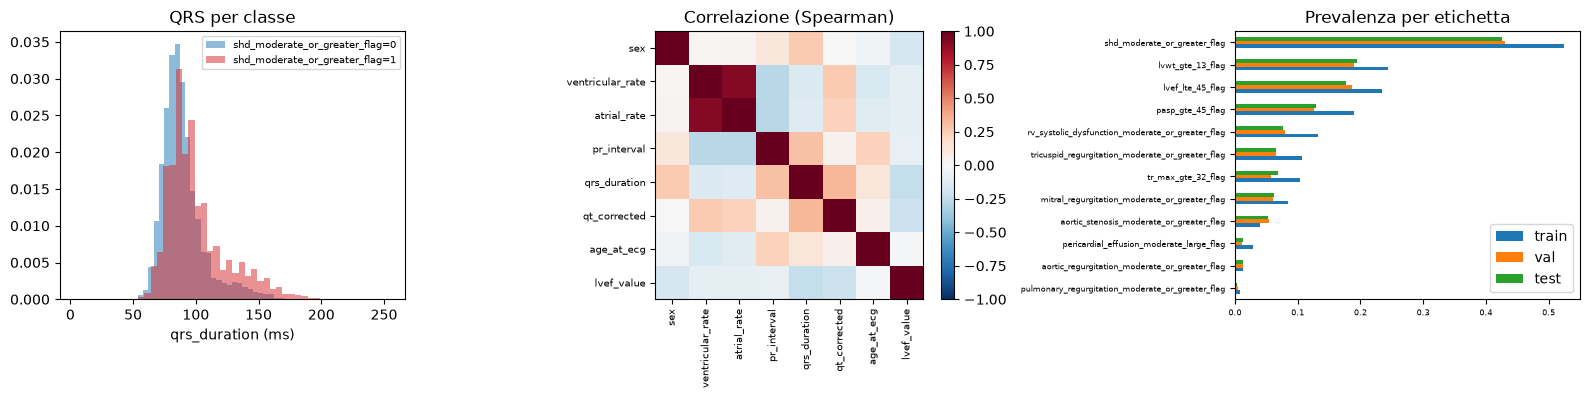

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
d = train.dropna(subset=[TARGET])
for v, c in [(0, "tab:blue"), (1, "tab:red")]:
    ax[0].hist(d.loc[d[TARGET] == v, "qrs_duration"].dropna(), bins=50, alpha=.5, density=True, color=c, label=f"{TARGET}={v}")
ax[0].set_xlabel("qrs_duration (ms)"); ax[0].legend(fontsize=7); ax[0].set_title("QRS per classe")
corr = train[ECG_FEATURES + ["lvef_value"]].corr(method="spearman")
im = ax[1].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); ax[1].set_xticks(range(len(corr))); ax[1].set_yticks(range(len(corr)))
ax[1].set_xticklabels(corr.columns, rotation=90, fontsize=7); ax[1].set_yticklabels(corr.columns, fontsize=7); ax[1].set_title("Correlazione (Spearman)")
plt.colorbar(im, ax=ax[1])
prev_s = prev[["train", "val", "test"]].sort_values("train")
prev_s.plot.barh(ax=ax[2]); ax[2].tick_params(labelsize=6); ax[2].set_title("Prevalenza per etichetta")
plt.tight_layout(); plt.show()

## 3 · Baseline sul target composito

Si confrontano due insiemi di feature:
- **solo età + sesso**: quanto si ottiene con la sola demografia;
- **tutte le feature ECG tabulari**: il valore aggiunto delle misure ECG.

Se la seconda non supera nettamente la prima, le misure tabulari aggiungono poco e conviene guardare le forme d'onda (notebook 04). Tutti gli AUROC sono calcolati su **validation**, con IC al 95%. Il test set non viene toccato.

,feature_set,model,AUROC,CI_lo,CI_hi,AUPRC,prev_val,n_val,sec
0,solo età+sesso,mlp_dense,0.659,0.642,0.675,0.582,0.43,4626,2.3
1,solo età+sesso,lasso_logreg,0.655,0.639,0.670,0.569,0.43,4626,0.5
2,solo età+sesso,logreg,0.655,0.639,0.669,0.569,0.43,4626,0.5
3,solo età+sesso,hist_gb,0.654,0.637,0.671,0.577,0.43,4626,0.6
4,solo età+sesso,random_forest,0.650,0.634,0.667,0.574,0.43,4626,1.1
5,tutte le feature ECG tabulari,hist_gb,0.746,0.733,0.759,0.699,0.43,4626,0.7
6,tutte le feature ECG tabulari,mlp_dense,0.745,0.730,0.759,0.694,0.43,4626,3.2
7,tutte le feature ECG tabulari,random_forest,0.741,0.727,0.754,0.692,0.43,4626,2.5
8,tutte le feature ECG tabulari,lasso_logreg,0.738,0.725,0.753,0.682,0.43,4626,0.5
9,tutte le feature ECG tabulari,logreg,0.738,0.725,0.753,0.682,0.43,4626,0.6


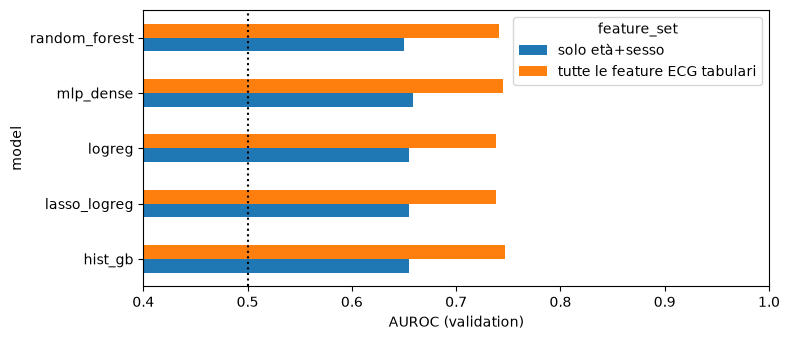

In [4]:
res = []
for fs_name, fs in {"solo età+sesso": ["age_at_ecg", "sex"], "tutte le feature ECG tabulari": ECG_FEATURES}.items():
    Xtr, ytr, _ = get_xy(train, TARGET, fs); Xva, yva, _ = get_xy(val, TARGET, fs)
    r, _ = eval_models(Xtr, ytr, Xva, yva); r.insert(0, "feature_set", fs_name); res.append(r)
baseline = pd.concat(res, ignore_index=True)
display(baseline.round(3))
baseline.to_csv(OUT_DIR / "00_baseline.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 3.5))
piv = baseline.pivot(index="model", columns="feature_set", values="AUROC")
piv.plot.barh(ax=ax); ax.axvline(0.5, color="k", ls=":"); ax.set_xlim(0.4, 1); ax.set_xlabel("AUROC (validation)")
plt.tight_layout(); plt.show()

### Controllo di coerenza: CV raggruppata per paziente sul train

Se l'AUROC in cross-validation sul train è molto più alto di quello su validation, c'è leakage tra ECG dello stesso paziente o un cambiamento di distribuzione tra split.

In [5]:
Xtr, ytr, dtr = get_xy(train, TARGET)
oof = oof_proba(model_zoo()["hist_gb"], Xtr, ytr, dtr.patient_key.values)
print("AUROC CV raggruppata (train, hist_gb):", round(safe_auc(ytr, oof), 3))
# Importanza delle feature (permutation importance su validation)
from sklearn.inspection import permutation_importance
Xva, yva, _ = get_xy(val, TARGET)
m = model_zoo()["hist_gb"].fit(Xtr, ytr)
pi = permutation_importance(m, Xva, yva, scoring="roc_auc", n_repeats=10, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=ECG_FEATURES).sort_values(ascending=False)
display(imp.round(4).to_frame("calo di AUROC se permutata"))

AUROC CV raggruppata (train, hist_gb): 0.728


,calo di AUROC se permutata
qt_corrected,0.0628
age_at_ecg,0.0389
qrs_duration,0.0309
pr_interval,0.0251
sex,0.0094
ventricular_rate,0.0052
atrial_rate,0.0033


## Come leggere il risultato

- **AUROC ≈ 0.5–0.6 con tutte le feature tabulari**: le sole misure ECG automatiche portano poco segnale per il target composito. È un risultato atteso e va comunicato ai partner: non è un errore del collega.
- **AUROC molto più alto di "solo età+sesso"**: c'è segnale nelle misure ECG e vale la pena cercare sottogruppi (notebook 01-03).
- Il segnale forte di EchoNext sta nelle forme d'onda a 12 derivazioni: vedi notebook 04.

I risultati sono salvati in `OUT_DIR` come CSV, da riusare nel confronto finale.